In [63]:
import numpy as np
import matplotlib.pyplot as plt
import h5py as h5
from sklearn.ensemble import RandomForestRegressor as RFR
from sklearn.model_selection import train_test_split as tts
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from seaborn import color_palette as cpal
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate as cv
from sklearn.metrics import roc_curve
from astroML.utils import completeness_contamination
from sklearn.metrics import confusion_matrix

In [41]:
f = h5.File('sample_2e7_design_precessing_higherordermodes_3detectors.h5', 'r')
fkeys = list(f.keys())
for i in range(len(fkeys)):
    print(i, fkeys[i])

0 chi1x
1 chi1y
2 chi1z
3 chi2x
4 chi2y
5 chi2z
6 dec
7 det
8 iota
9 mtot
10 psi
11 q
12 ra
13 snr
14 z


In [42]:
for k in f.keys(): lensample = f[k].size #print(lensample)
nkeys = np.shape(fkeys)[0]
nfeat = nkeys - 2

ffeat = []
X = np.zeros((nfeat, lensample))
j = 0
for i in range(nkeys):
    if i == 7: continue
    if i == 13: continue
    #print(j)
    ffeat.append(fkeys[i])
    X[j] = f[fkeys[i]]
    print(j, fkeys[i])
    j += 1

X = X.T

y = f['det']
y = np.array(y)

0 chi1x
1 chi1y
2 chi1z
3 chi2x
4 chi2y
5 chi2z
6 dec
7 iota
8 mtot
9 psi
10 q
11 ra
12 z


In [43]:
f.close()

let's work on a subsample to reduce the computing time

In [44]:
ss_size = int(1e6)
X = X[:ss_size]
y = y[:ss_size]
print(X.shape, y.shape)

(1000000, 13) (1000000,)


In [45]:
X_train, X_test, y_train, y_true = tts(X, y, train_size=0.67, random_state = 22)

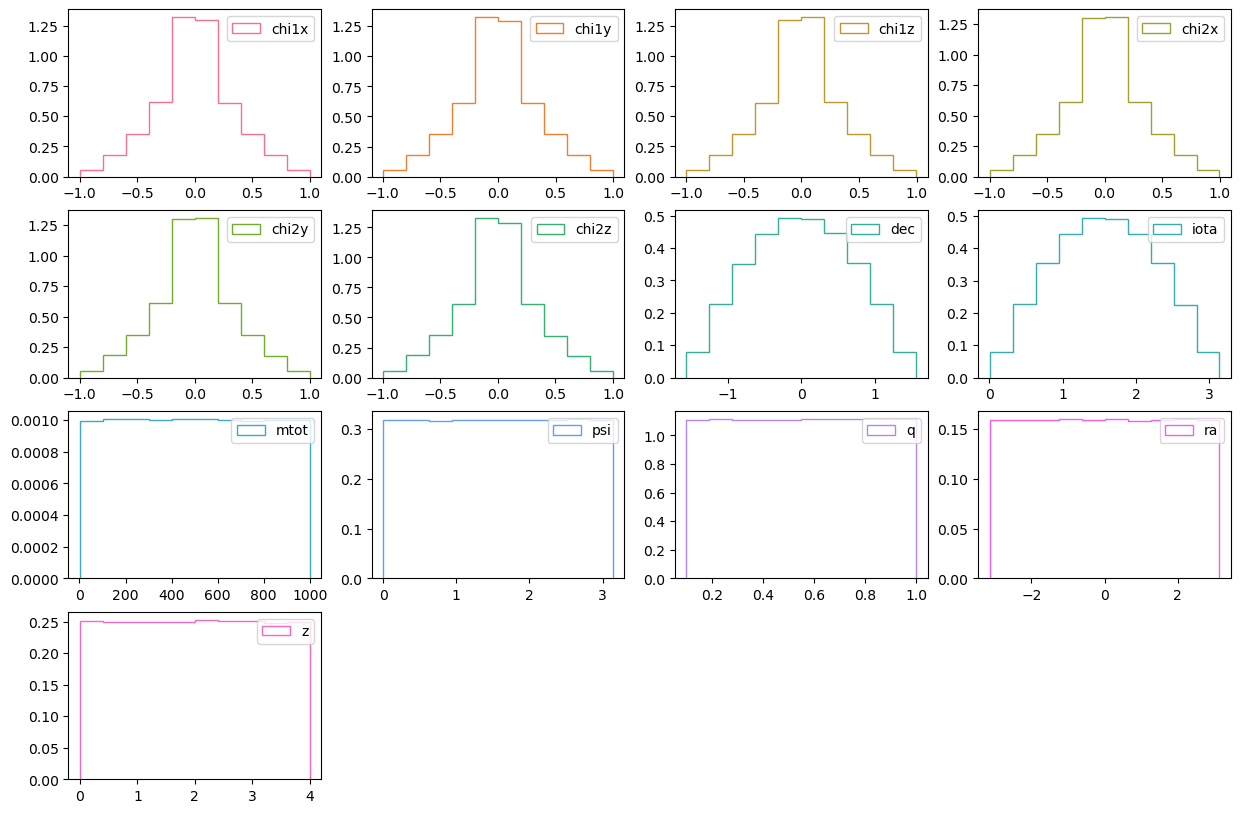

In [46]:
colors = cpal('husl', nfeat)
fig, axes = plt.subplots(ncols=4, nrows=4, figsize=(15,10))
axes = axes.flatten()
for i in range(len(axes)):
    if i >= 13:
        fig.delaxes(axes[i])
        continue
    axes[i].hist(X_train[:,i], color=colors[i], histtype='step', density=True, label=ffeat[i])
    axes[i].legend(loc='upper right')
plt.show()

In [47]:
rfr = RFR()
rfr.fit(X_train[:int(5e4)], y_train[:int(5e4)]) #had to shrink the sample which I applied the RFR on bc it got to 112 mins of execution and the process wasn't even over 
importances = rfr.feature_importances_
forder = np.argsort(importances)[::-1] #features order
print(forder)

[12  8  7 10  2  5 11  1  6  0  4  3  9]


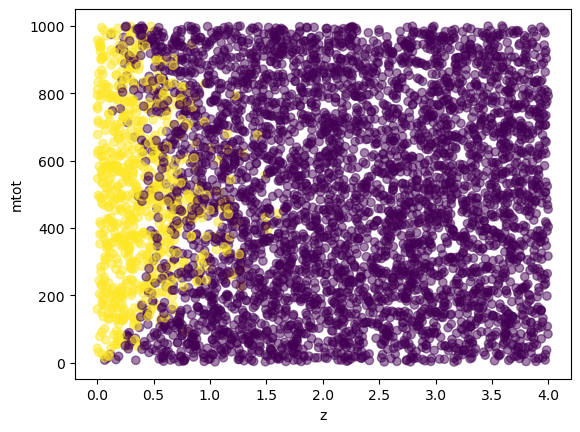

In [48]:
plt.scatter(X_train[:int(5e3),forder[0]], X_train[:int(5e3),forder[1]], ls='None', c=y_train[:int(5e3)], marker='o', alpha=0.5)
plt.xlabel(ffeat[forder[0]])
plt.ylabel(ffeat[forder[1]])
plt.show()

Let's perform a quick preliminar DTC analysis

In [49]:
dtree = DecisionTreeClassifier(max_depth=3)
dtree.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=3)

In [50]:
dtree.score(X_test, y_true)

0.9411272727272727

In [51]:
y_pred = dtree.predict(X_test)

In [52]:
corr = np.zeros(len(y_true))
corr[np.where(y_pred == y_true)] = 1

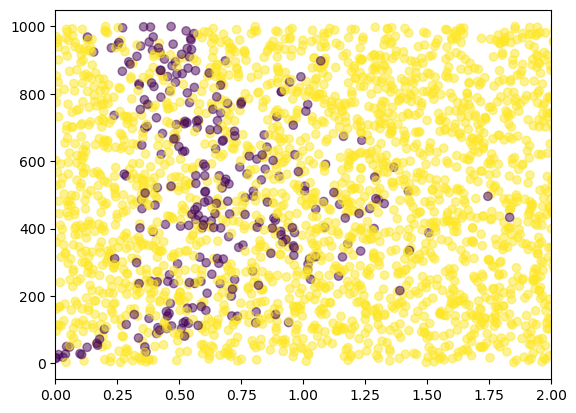

In [53]:
plt.scatter(X_test[:int(5e3),forder[0]], X_test[:int(5e3),forder[1]], ls='None', c=corr[:int(5e3)], marker='o', alpha=0.5)
plt.xlim(0,2)
plt.show()

* purple dots are the wrong predicted ones

Let's now perform a Cross Validation analysis

In [ ]:
depths = [3,6,9,12,15]
scores = np.zeros(len(depths))
completeness = np.zeros(len(depths))
contamination = np.zeros(len(depths))
for i in tqdm(range(len(depths))):
    depth = int(depths[i])
    dtree = DecisionTreeClassifier(max_depth=depth)
    dtree.fit(X_train, y_train)
    crossval = cv(dtree, X=X_train, y=y_train, cv=4, scoring='accuracy')
    scores[i] = np.mean(crossval['test_score'])
    y_pred = dtree.predict(X_test)
    completeness[i], contamination[i] = completeness_contamination(y_pred, y_true)

print(scores)

100%|██████████| 5/5 [03:35<00:00, 43.14s/it]

[0.94109403 0.95425075 0.96094179 0.96209552 0.96006567]


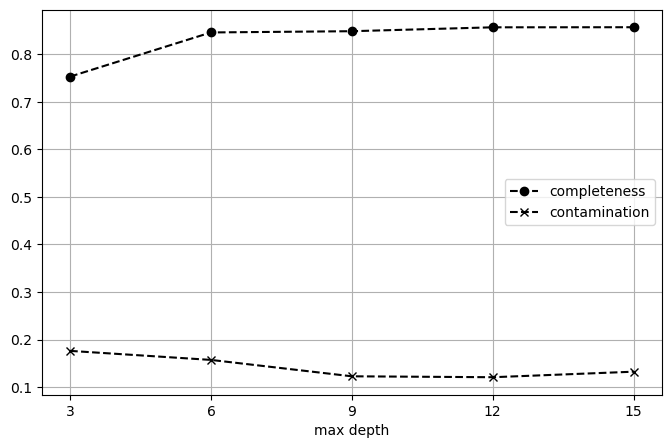

In [55]:
fig, ax = plt.subplots(figsize=(8,5))
plt.plot(depths, completeness, c='black', ls='dashed', marker='o', label='completeness')
plt.plot(depths, contamination, c='black', ls='dashed', marker='x', label='contamination')
plt.grid()
plt.xlabel('max depth')
plt.xticks(depths)
plt.legend()
plt.show()

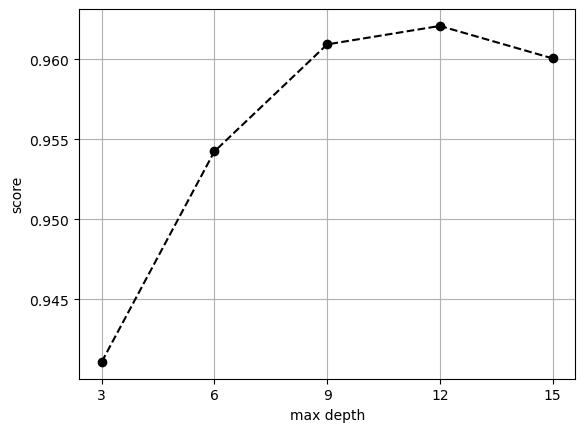

In [56]:
plt.plot(depths, scores, marker='o', c='black', ls='dashed')
plt.xlabel('max depth')
plt.ylabel('score')
plt.xticks(depths)
plt.grid()
plt.show()

In [57]:
best_depth = int(depths[np.argmax(scores)])
best_depth

12

In [60]:
dtree = DecisionTreeClassifier(max_depth=best_depth)
dtree.fit(X_train,y_train)
print(dtree.score(X_test, y_true))
y_pred = dtree.predict(X_test)
corr = np.zeros(len(y_true))
corr[np.where(y_pred == y_true)] = 1

0.9624060606060606


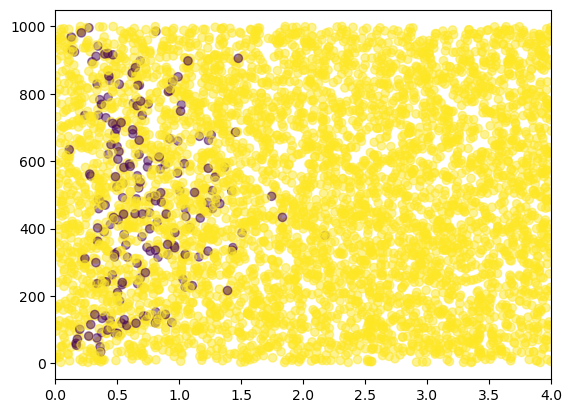

In [67]:
plt.scatter(X_test[:int(5e3),forder[0]], X_test[:int(5e3),forder[1]], ls='None', c=corr[:int(5e3)], marker='o', alpha=0.5)
plt.xlim(0,4)
plt.show()

* purple dots are still the wrong predictions wrt y_true

In [64]:
confusion_matrix(y_true, y_pred)

array([[276788,   5583],
       [  6823,  40806]])